# GW250114: Informed-sky ringdown analysis

Informed-sky uses the Full-sky likelihood (both detectors analysed from the arrival time at Hanford, the last detector,
with the sky-dependent delay in the Livingston template), but replaces the isotropic sky prior with the IMR sky posterior.
The posterior is represented by K = 100 equal-weight samples, and the sky is summed out inside the likelihood:

$$\ln \mathcal{L}_{\rm inf}(\theta) = \ln \frac{1}{K}\sum_{k=1}^{K} \mathcal{L}_{\rm Full}(\theta, \alpha_k, \delta_k),$$

so the sampler only sees $M$, $\chi$, the amplitudes and phases, $\cos\iota$ and $\psi$. The IMR sky posterior also contains the ringdown data, so this double-counts it
slightly; it is used only for GW250114, whose localization is set mainly by the inspiral.

Set `SKYRING_DATA` to the unzipped Zenodo data (IMR sky samples and strain), or provide the IMR (ra, dec) samples in
`IMR_SKY`. Nothing is saved to disk.

In [1]:
import os
os.environ["JAX_PLATFORM_NAME"] = "cpu"
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=12"   # CPU devices used by the sampler; before importing jax
os.environ["PATH"] = "/Library/TeX/texbin" + os.pathsep + os.environ["PATH"]   # the plots render text with LaTeX
import sys
sys.path.insert(0, '../src')
import time
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import numpy as onp
import jax
import jax.numpy as jnp
from jax.scipy.special import logsumexp
import lal
import numpyro
import numpyro.distributions as dist
from numpyro.contrib.nested_sampling import NestedSampler

import waveform as wf
from swsh import swsh
from other_utils import bandpass_ds, analysis_data, td_acf, cholesky_from_acf, decode_termination
from strain_cache import fetch_or_cache_strain
from plot_utils import make_corner_plot, make_amplitude_ratio_plot

jax.config.update("jax_enable_x64", True)
numpyro.enable_x64()
quiet = lambda *a, **k: None

/Users/kallol/miniconda3/envs/skyring/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/kallol/miniconda3/envs/skyring/lib/python3.12/site-packages/jaxns/internals/mixed_precision.py:14: UserWarning: JAX x64 is not enabled. Setting it now. Check for errors.
  warnings.warn("JAX x64 is not enabled. Setting it now. Check for errors.")
INFO:2026-11-25 14:17:22,734:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/kallol/miniconda3/envs/skyring/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': I

In [12]:
## Settings of the paper's GW250114 Informed-sky runs
t_peak, tM = 1420878141.235932, 0.337e-3      # geocentric peak time [GPS] and t_M = G M_f / c^3 (M_f = 68.4 Msun) [s]
t_start = t_peak + 6 * tM                     # geocentric ringdown start
ra, dec = 2.33, 0.19                          # IMR point estimate: only sets the arrival times and the reference detector
acf_centers = (t_peak - 34, t_peak + 34)      # 64 s off-source stretches, ending 2 s before / starting 2 s after t_peak
modes, modes_220 = ((2, 2, 0), (2, 2, 1)), ((2, 2, 0),)
mass = (55., 95.)
amp = {(2, 2, 0): (0., 4.), (2, 2, 1): (0., 4.)}   # in units of 1e-20
K, NODE_SEED = 100, 31567                     # number of IMR sky samples (quadrature nodes) and the seed that draws them
detectors = ("H1", "L1")
seglen, fs, srate, T, t0, trim = 8, 16384, 4096, 0.2, 0.0, 0.25
acf_seglen, taper = 64.0, 0.1
chi = (0., 0.99)

DATA = os.environ.get("SKYRING_DATA", "../../skyring_zenodo_v3/posterior_files/")      # the unzipped Zenodo data (see README)
# DATA = os.environ.get("SKYRING_DATA")
STRAIN = os.path.join(DATA, "strain") if DATA else "./strain_cache"
NLIVE = int(os.environ.get("SKYRING_NLIVE", 10_000))
## IMR sky samples (ra, dec) of GW250114 from the LVK GWTC-5 release, dataset C00:NRSur7dq4, in their original order:
## imr_sky/ of the Zenodo data, or the 'ra' and 'dec' columns of GW250114_082203.hdf5 (C00:NRSur7dq4/posterior_samples)
IMR_SKY = os.path.join(DATA, "imr_sky", "GW250114_C00_NRSur7dq4_sky.npz") if DATA else "GW250114_C00_NRSur7dq4_sky.npz"

In [13]:
## 1. Strain and arrival times at the fixed IMR sky position
raw = {ifo: fetch_or_cache_strain(ifo, t_start - seglen/2, t_start + seglen/2, fs, STRAIN, log=quiet) for ifo in detectors}
det = {"H1": lal.CachedDetectors[lal.LALDetectorIndexLHODIFF], "L1": lal.CachedDetectors[lal.LALDetectorIndexLLODIFF]}
t_lal = lal.LIGOTimeGPS(t_start)
gmst = float(lal.GreenwichMeanSiderealTime(t_lal))
t_arrival = {ifo: t_start + lal.TimeDelayFromEarthCenter(det[ifo].location, ra, dec, t_lal) for ifo in detectors}
ref_det = max(t_arrival, key=t_arrival.get)            # the last detector to see the signal
t_ref = t_arrival[ref_det]
for ifo in detectors:
    print(f"{ifo}: arrival {t_arrival[ifo]:.6f} ({(t_arrival[ifo] - t_ref) * 1e3:+.3f} ms from {ref_det})")

H1: arrival 1420878141.221026 (+0.000 ms from H1)
L1: arrival 1420878141.218555 (-2.470 ms from H1)


In [14]:
## 2. Conditioning and analysis windows (n samples of 0.2 s at 4096 Hz)
n = wf.Ntime(srate, T)
def window(ifo, t_begin):
    """Condition the strain so that a sample falls on t_begin, then take n samples from the one closest to it."""
    times, data = bandpass_ds(raw[ifo], t0=t_begin, ds=fs // srate, trim=trim, f_min=None)   # no high-pass
    return jnp.asarray(analysis_data(data, times, t_begin, n)[1], dtype=jnp.float64)

h_full = {ifo: window(ifo, t_ref) for ifo in detectors}               # Full-sky: common start at t_ref
first = min(t_arrival, key=t_arrival.get)
print(f"{n} samples per detector; Full-sky drops the first {(t_ref - t_arrival[first]) * 1e3:.2f} ms of the {first} ringdown")

820 samples per detector; Full-sky drops the first 2.47 ms of the L1 ringdown


In [15]:
## 3. Noise covariance: average time-domain autocorrelation of the off-source stretches, then its Cholesky factor
acf = {ifo: [] for ifo in detectors}
for c in acf_centers:
    for ifo in detectors:
        stretch = fetch_or_cache_strain(ifo, c - acf_seglen/2, c + acf_seglen/2, fs, STRAIN, log=quiet)
        times, data = bandpass_ds(stretch, t0=c, ds=fs // srate, trim=trim, f_min=None)   # conditioned like the data
        acf[ifo].append(td_acf(data, n, taper=taper))
L = {ifo: cholesky_from_acf(onp.mean(acf[ifo], axis=0)) for ifo in detectors}           # C = L L^T

## detector responses and locations used by the likelihoods
wf.set_detectors(*(jnp.asarray(det[ifo].response, dtype=jnp.float64) for ifo in detectors))
wf.set_detector_locations(*wf.initialize_det_locs())

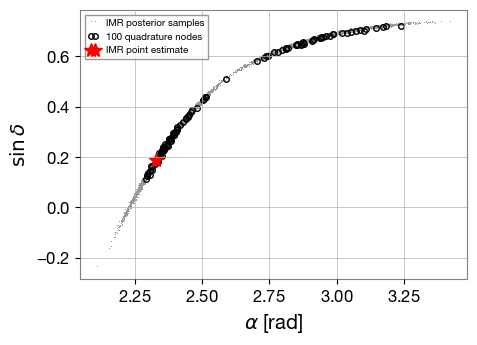

In [16]:
## 4. The sky prior: K IMR posterior samples with equal weights (the quadrature nodes)
imr = onp.load(IMR_SKY)
ext = onp.array([imr["ra"], onp.sin(imr["dec"])]).T                               # (ra, sin dec)
nodes = jnp.asarray(ext[onp.random.default_rng(NODE_SEED).integers(0, len(ext), K)])
logw = jnp.full(K, -onp.log(K))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(ext[:, 0], ext[:, 1], ",", color="0.6", label="IMR posterior samples")
ax.plot(onp.asarray(nodes)[:, 0], onp.asarray(nodes)[:, 1], "o", mfc="none", mec="k", ms=4, label=f"{K} quadrature nodes")
ax.plot(ra, onp.sin(dec), "r*", ms=10, label="IMR point estimate")
ax.set_xlabel(r"$\alpha$ [rad]"); ax.set_ylabel(r"$\sin\delta$"); ax.legend(fontsize=7)
plt.show()

In [17]:
## 5. Informed-sky log-likelihood: the Full-sky likelihood averaged over the sky nodes,
##    ln L(theta) = ln[ (1/K) sum_k L_Full(theta, sky_k) ],  theta = [M, chi, (A, phi) per mode, cos iota, psi]
def swsh_fn(l, m, iota):
    return swsh(2, l, m, iota, 0.0)

def make_informed_loglik(md):
    table = wf.load_qnm_table("../data", md)
    loglik_full = lambda th: wf.ln_likelihood_general_full_jit(h_full["H1"], h_full["L1"], th, gmst, L["H1"], L["L1"],
                                                                table, md, swsh_fn, T, srate, t0, ref_det)
    i_ra = 3 + 2 * len(md)                                       # where (ra, sin dec) go in the Full-sky vector
    def loglik(theta):
        th = jnp.broadcast_to(theta, (K, theta.shape[0]))
        return logsumexp(jax.vmap(loglik_full)(jnp.concatenate([th[:, :i_ra], nodes, th[:, i_ra:]], axis=1)) + logw)
    return loglik

def prior_box(md):
    low, high = [mass[0], chi[0]], [mass[1], chi[1]]
    for mode in md:
        low += [amp[mode][0], 0.]; high += [amp[mode][1], 2*onp.pi]           # amplitude, phase
    low += [-1., 0.]; high += [1., onp.pi]                                    # cos iota, psi (no sky parameters)
    return jnp.array(low), jnp.array(high)

In [ ]:
## Nested sampling (jaxns through numpyro): stops when ln(Z_dead + Z_live) - ln(Z_dead) < 0.01
def nested_sampling(loglik, low, high, nlive=NLIVE, seed=31567, max_samples=None, label=""):
    def model():
        theta = numpyro.sample("theta", dist.Uniform(low, high))
        numpyro.factor("loglike", loglik(theta))
    rng_run, rng_post = jax.random.split(jax.random.PRNGKey(seed))
    ns = NestedSampler(model, constructor_kwargs=dict(num_live_points=nlive, verbose=False,
                                                      max_samples=max_samples or max(500_000, 10 * nlive * len(low))),
                       termination_kwargs=dict(dlogZ=0.01))
    start = time.time()
    ns.run(rng_run)
    r = ns._results
    reasons, converged = decode_termination(int(r.termination_reason))
    theta = onp.asarray(ns.get_samples(rng_post, num_samples=100_000)["theta"])
    print(f"  {label:22s} ln Z = {float(r.log_Z_mean):.2f} +- {float(r.log_Z_uncert):.2f} "
          f"({'converged' if converged else 'NOT converged: ' + ', '.join(reasons)}; {(time.time() - start) / 60:.1f} min)")
    return theta, float(r.log_Z_mean), float(r.log_Z_uncert)

In [ ]:
## 6. Both models and ln B.
##    Each likelihood call evaluates the Full-sky likelihood K = 100 times: with 1e4 live points the two runs took
##    about 6 h and 2.5 h on a laptop.
out = {}
for md in (modes, modes_220):
    low, high = prior_box(md)
    out[md] = nested_sampling(make_informed_loglik(md), low, high, seed=31567 ^ 0xABCDEF, max_samples=500_000,
                              label=f"informed-sky {'+'.join(''.join(map(str, m)) for m in md)}")
theta, lnZ, err = out[modes]; _, lnZ_220, err_220 = out[modes_220]
ratio = theta[:, 4] / theta[:, 2]
print(f"Informed-sky: ln B = {lnZ - lnZ_220:.2f} +- {onp.hypot(err, err_220):.2f} (the paper: 7.66 +- 0.06); "
      f"A221/A220 median {onp.median(ratio):.3f} [{onp.percentile(ratio, 5):.3f}, {onp.percentile(ratio, 95):.3f}]")

In [ ]:
## 7. Informed-sky posterior (68% and 95% regions) and the amplitude ratio
names = ["M", "chi", "A220", "phi220", "A221", "phi221", "cosiota", "psi"]
def latex(name):
    if name.startswith("A"):
        return rf"$A_{{{name[1:]}}}\,[10^{{-20}}]$"
    if name.startswith("phi"):
        return rf"$\phi_{{{name[3:]}}}$"
    return {"M": r"$M$", "chi": r"$\chi$", "cosiota": r"$\cos\iota$", "psi": r"$\psi$"}[name]
labels = [latex(x) for x in names]
datasets = [{"samples": theta, "params": labels, "label": "Informed-sky", "color": "#218709"}]
make_corner_plot(datasets=datasets, full_sky_params=labels)
make_amplitude_ratio_plot(datasets=datasets, numerator_index=4, denominator_index=2, ratio_label=r"$A_{221}/A_{220}$", bins=60)